# P5b · AVD: análise exploratória do recorte Elliptic++

Dados: `data/dataset_parte2/` (14.182 carteiras, 25.111 arestas).
Pergunta de pesquisa: *Carteiras ilícitas participam mais de ciclos de repasse (ciclos negativos) do que as lícitas?*

Etapas: 1. carga · 2. estrutural · 3. distribucional · 4. faltantes · 5. relacional · 6. outliers · 7. gráficos exploratórios · 8. gráficos explanatórios · 9. da exploração à explicação.

> Regra do projeto: a **escolha do tipo de gráfico** e a **interpretação** são do Vagner (não da IA).
> Células de código escritas com apoio de IA estão marcadas com `# [IA]`. Textos em markdown são do Vagner, salvo indicação na própria célula; revisões de texto feitas com IA estão no `docs/REGISTRO_IA.md`.

## 1. Carga dos dados

In [ ]:
# [IA] Claude Code – importação e definiçção de variáveis
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PASTA = "../../data/dataset_parte2/"
SAIDA = "../../out/parte2/avd/"
os.makedirs(SAIDA, exist_ok=True)

nos = pd.read_csv(PASTA + "nos.csv")
arestas = pd.read_csv(PASTA + "arestas.csv")

print("nós:", nos.shape, "| arestas:", arestas.shape)
nos.head()

nós: (14182, 9) | arestas: (25111, 6)


,endereco,btc_received_total,btc_sent_total,total_txs,fees_total,lifetime_in_blocks,num_timesteps_appeared_in,saldo_btc,classe
0,111iu559diy1cBDTP9cRhy8sYYcECvvrw,0.028167,0.028167,2.0,0.000708,1.0,1.0,0.000000,ilicito
1,111khWGs3Mj7UgKT7aS6hLsYK11ii4Gmw,207.237033,240.848000,5.0,0.048075,40324.0,2.0,-33.610967,licito
2,1121LXUU8xwRaNqpBJDPjyRL1ctApsS4uU,0.006800,0.006800,2.0,0.046897,3.0,1.0,0.000000,ilicito
3,11238JxaWpG9UsmVapWF4kNkhH9hZhxYeh,3.136576,3.659237,6.0,0.008615,4.0,1.0,-0.522661,desconhecido
4,112GBCxMnbDkZdSSKVehkQ5F9YJQ9V8yA,0.005100,0.005100,2.0,0.004992,7.0,1.0,0.000000,desconhecido


In [4]:
# [IA] Claude Code – tipos das colunas
nos.dtypes

endereco                         str
btc_received_total           float64
btc_sent_total               float64
total_txs                    float64
fees_total                   float64
lifetime_in_blocks           float64
num_timesteps_appeared_in    float64
saldo_btc                    float64
classe                           str
dtype: object

In [5]:
# [IA] Claude Code – primeiras arestas
arestas.head()

,origem,destino,peso,valor_btc,n_txs,valor_faltante
0,1121LXUU8xwRaNqpBJDPjyRL1ctApsS4uU,3JUgPFWr3kMLrm1cauMcgcEMm6RZtLWnnM,6.306893,6.306893,1,False
1,11238JxaWpG9UsmVapWF4kNkhH9hZhxYeh,124wEpEZZG4ZyDEYDchC9vGZjrGyoVUmi8,0.000000,8.718053,1,False
2,11238JxaWpG9UsmVapWF4kNkhH9hZhxYeh,195eqvV43dFxexf4cqEWzmCgNXNiyeecmS,0.000000,24.009933,1,False
3,11238JxaWpG9UsmVapWF4kNkhH9hZhxYeh,1Bg9bJSvzpwdBTTP2QK2qjwpYrkvzeCiqv,0.000000,24.009933,1,False
4,11238JxaWpG9UsmVapWF4kNkhH9hZhxYeh,1F3mTdpMFvs8WhKgJtFhXgdL83TkTPBEWc,0.000000,8.718053,1,False


## 2. Estrutural

In [6]:
print("Nós:", len(nos))
print("Arestas:", len(arestas))
print("Arestas com peso < 0:", (arestas["peso"] < 0).sum())
print("Arestas com peso = 0:", (arestas["peso"] == 0).sum())
# [IA] Claude Code – densidade dirigida = |E| / (|V| (|V| − 1))
print("Densidade:", len(arestas) / (len(nos) * (len(nos) - 1)))
nos["classe"].value_counts()

Nós: 14182
Arestas: 25111
Arestas com peso < 0: 3279
Arestas com peso = 0: 8658
Densidade: 0.00012485894757635662


classe
ilicito         5208
desconhecido    4713
licito          4261
Name: count, dtype: int64

In [7]:
# [IA] Claude Code – graus de entrada e saída contados com pandas (não usa graph.py)
grau_saida = arestas.groupby("origem").size()
grau_entrada = arestas.groupby("destino").size()

nos["grau_saida"] = nos["endereco"].map(grau_saida).fillna(0).astype(int)
nos["grau_entrada"] = nos["endereco"].map(grau_entrada).fillna(0).astype(int)

nos[["grau_entrada", "grau_saida"]].describe()

,grau_entrada,grau_saida
count,14182.000000,14182.000000
mean,1.770625,1.770625
std,30.511869,9.672418
min,0.000000,0.000000
25%,0.000000,1.000000
50%,0.000000,1.000000
75%,1.000000,1.000000
max,2719.000000,1002.000000



Consegui observar que possuímos mais arestas com peso positivo (13.174, 52,5%), mas ainda possuímos muitas arestas com peso nulo e negativo (8.658, 34,5%, e 3.279, 13,1%, respectivamente). O peso neste projeto funciona da seguinte forma: o peso de uma aresta A → B é o saldo líquido da carteira de destino B, ou seja, o total de BTC recebido menos o total enviado. Peso positivo indica que B acumula BTC, negativo indica que B repassa mais do que recebe, e nulo indica que B envia tudo o que recebe.

Em relação à classe das carteiras (ilícito, lícito e desconhecido), temos valores parecidos entre os grupos: 5.208 ilícitas (36,7%), 4.713 desconhecidas (33,2%) e 4.261 lícitas (30,0%).

Além disso, os graus de entrada e de saída têm a mesma média (1,77), o que é esperado, pois cada aresta soma 1 na saída de uma carteira e 1 na entrada de outra. Porém, há uma diferença significativa no desvio padrão entre eles (30,51 no grau de entrada contra 9,67 no grau de saída): poucas carteiras recebem de muitas outras (o maior grau de entrada é 2.719, contra 1.002 no de saída).

A densidade do gráfo é próxima de 0, então é um grafo esparso em que dificilmente podemos encontrar quais carteiras, determinada carteira está ligada.

## 3. Distribucional

In [8]:
# [IA] Claude Code – lista dos atributos numéricos das carteiras
ATRIBUTOS = nos.select_dtypes("number").columns.tolist()
ATRIBUTOS

['btc_received_total',
 'btc_sent_total',
 'total_txs',
 'fees_total',
 'lifetime_in_blocks',
 'num_timesteps_appeared_in',
 'saldo_btc',
 'grau_saida',
 'grau_entrada']

In [9]:
# [IA] Claude Code – estatísticas de cada atributo das carteiras
nos[ATRIBUTOS].describe().T

,count,mean,std,min,25%,50%,75%,max
btc_received_total,14182.0,2.016689,70.304372,0.000000,0.000000,0.003792,0.016198,6610.127256
btc_sent_total,14182.0,2.974309,167.395212,0.000000,0.002000,0.005100,0.024080,19195.848900
total_txs,14182.0,2.092512,8.891691,1.000000,1.000000,2.000000,2.000000,639.000000
fees_total,14182.0,0.030692,0.060530,0.000000,0.002468,0.004892,0.039292,2.108203
lifetime_in_blocks,14182.0,1362.787830,7336.365419,0.000000,0.000000,1.000000,3.000000,96767.000000
num_timesteps_appeared_in,14182.0,1.119306,0.796479,1.000000,1.000000,1.000000,1.000000,39.000000
saldo_btc,14182.0,-0.957620,107.557803,-12585.721644,-0.004737,0.000000,0.000000,1078.828715
grau_saida,14182.0,1.770625,9.672418,0.000000,1.000000,1.000000,1.000000,1002.000000
grau_entrada,14182.0,1.770625,30.511869,0.000000,0.000000,0.000000,1.000000,2719.000000


In [10]:
# [IA] Claude Code – estatísticas dos atributos das arestas
arestas[["peso", "valor_btc", "n_txs"]].describe().T

,count,mean,std,min,25%,50%,75%,max
peso,25111.0,-50.369053,547.880705,-12585.721644,0.000000,0.003737,2.054115,1078.828715
valor_btc,25111.0,46.093009,176.194548,0.000250,1.434474,4.000000,12.676157,6838.178522
n_txs,25111.0,1.014974,0.226515,1.000000,1.000000,1.000000,1.000000,22.000000


In [ ]:
# [IA] Claude Code – cálculo dos números citados na nota da seção 3
print("Carteiras com saldo exatamente zero (%):", round(100 * (nos["saldo_btc"] == 0).mean(), 1))
print("Menor e maior saldo (BTC):", round(nos["saldo_btc"].min(), 2), round(nos["saldo_btc"].max(), 2))

muito_negativas = arestas[arestas["peso"] < -100]
print("Arestas com peso < -100:", len(muito_negativas))
print("Carteiras de destino dessas arestas:", muito_negativas["destino"].nunique())
print("Soma do peso dessas arestas:", round(muito_negativas["peso"].sum(), 2))
print("Soma do peso das demais arestas:", round(arestas.loc[arestas["peso"] >= -100, "peso"].sum(), 2))

print("Pares com n_txs = 1 (%):", round(100 * (arestas["n_txs"] == 1).mean(), 1))

Na maioria dos atributos, os valores ficam concentrados nos números pequenos, mas algumas carteiras apresentam valores muito altos. Por isso, a média acaba ficando bem maior que a mediana, e o desvio padrão também costuma ser alto. O BTC recebido tem mediana de 0,0038 e média de 2,02. No BTC enviado, a mediana é 0,0051 e a média é 2,97, chegando ao máximo de 19.196 BTC. O número de transações tem mediana 2 e máximo de 639. Em geral, uma carteira movimenta pouco BTC, enquanto poucas carteiras muito grandes concentram a maior parte do volume.

O saldo funciona de um jeito um pouco diferente. Mais da metade das carteiras (52,4%) tem saldo exatamente zero. Mesmo assim, existem alguns saldos negativos muito altos: os valores vão de −12.586 a +1.079 BTC. Por causa desses valores extremos, a média (−0,96) fica abaixo da mediana (0).

Nas ligações entre as carteiras, o peso tem média de −50,37 e mediana de 0,0037. A média fica negativa por causa de poucos casos muito extremos: as 754 ligações com peso abaixo de −100 pertencem a apenas 4 carteiras e, juntas, têm um peso maior que o total das outras ligações. Isso acontece porque o saldo da carteira de destino é repetido em todas as ligações que chegam até ela. O valor_btc tem mediana 4 e média 46,1. O n_txs é quase sempre 1: isso acontece em 99% dos pares, com média de 1,01 e máximo de 22. Portanto, cada par de carteiras normalmente faz uma única transação. O num_timesteps_appeared_in também tem mediana 1, o que significa que a maioria das carteiras aparece em apenas um intervalo de tempo.

Em resumo, a média sozinha pode dar uma impressão errada sobre esses dados, porque poucos valores muito altos ou muito baixos influenciam bastante o resultado. Por isso, nos gráficos usamos principalmente medianas e proporções.

## 4. Dados faltantes

In [11]:
# [IA] Claude Code – nulos por coluna
print("Nulos em nos.csv:")
print(nos.isna().sum())
print()
print("Nulos em arestas.csv:")
print(arestas.isna().sum())

Nulos em nos.csv:
endereco                     0
btc_received_total           0
btc_sent_total               0
total_txs                    0
fees_total                   0
lifetime_in_blocks           0
num_timesteps_appeared_in    0
saldo_btc                    0
classe                       0
grau_saida                   0
grau_entrada                 0
dtype: int64

Nulos em arestas.csv:
origem            0
destino           0
peso              0
valor_btc         0
n_txs             0
valor_faltante    0
dtype: int64


In [12]:
# [IA] Claude Code – a classe "desconhecido" é o rótulo ausente
nos["classe"].value_counts(normalize=True).round(3)

classe
ilicito         0.367
desconhecido    0.332
licito          0.300
Name: proportion, dtype: float64

In [13]:
# [IA] Claude Code – compara carteiras sem rótulo com as rotuladas (não apaga nada)
nos["rotulado"] = nos["classe"] != "desconhecido"
nos.groupby("rotulado")[ATRIBUTOS].median().T

rotulado,False,True
btc_received_total,0.004900,0.00320
btc_sent_total,0.009949,0.00510
total_txs,2.000000,2.00000
fees_total,0.003530,0.00784
lifetime_in_blocks,1.000000,1.00000
num_timesteps_appeared_in,1.000000,1.00000
saldo_btc,0.000000,0.00000
grau_saida,1.000000,1.00000
grau_entrada,0.000000,0.00000


In [ ]:
# [IA] Claude Code – cálculo dos números citados na nota da seção 4
desconhecidas = set(nos.loc[nos["classe"] == "desconhecido", "endereco"])
toca_desconhecida = arestas["origem"].isin(desconhecidas) | arestas["destino"].isin(desconhecidas)
print("Arestas que somem ao excluir as desconhecidas:", toca_desconhecida.sum())
print("Proporção do total de arestas (%):", round(100 * toca_desconhecida.mean(), 1))

colunas = ["btc_received_total", "btc_sent_total", "fees_total"]
print()
print("Médias (rotulado = False são as desconhecidas):")
print(nos.groupby("rotulado")[colunas].mean().round(2))
print()
print("Medianas:")
print(nos.groupby("rotulado")[colunas].median().round(4))

Nenhuma coluna tem valores nulos. O único dado que falta é o rótulo de 4.713 carteiras, classificadas como “desconhecido”, o que representa 33,2% do recorte. No Elliptic++, esse rótulo é definido a partir das transações em que cada carteira aparece: ela é considerada ilícita se participou de pelo menos uma transação ilícita, lícita se participou apenas de transações lícitas e desconhecida quando participou somente de transações sem rótulo. Os rótulos dessas transações, porém, não estão disponíveis neste recorte. Por isso, não é possível afirmar que a falta do rótulo da carteira depende diretamente deles. Neste conjunto de dados, as carteiras desconhecidas apresentam diferenças em variáveis que conseguimos observar: elas têm medianas maiores para os valores recebidos e enviados e mediana menor para as taxas. Isso é uma evidência contra a ideia de que os rótulos estão ausentes completamente ao acaso (MCAR) e torna MAR uma hipótese plausível, pois a ausência do rótulo parece estar relacionada a características observadas no recorte. Ainda assim, não é possível descartar MNAR, já que a verdadeira classe da carteira pode ter influenciado a decisão de investigá-la ou rotulá-la, algo que não pode ser verificado com os dados disponíveis. As carteiras desconhecidas movimentam mais BTC quando usamos a mediana: 0,0049 contra 0,0032 no valor recebido e 0,0099 contra 0,0051 no valor enviado. Pela média, porém, movimentam um pouco menos: 1,99 contra 2,03 no recebido e 2,83 contra 3,04 no enviado. Elas também pagam menos taxas, com mediana de 0,0035 contra 0,0078. A classe “desconhecido” foi mantida como uma categoria própria, sem remover nenhuma linha. Excluir essas carteiras faria desaparecer 13.808 arestas, ou 55% das 25.111 arestas do recorte, incluindo tanto as arestas em que elas são origem quanto aquelas em que são destino. Isso poderia quebrar caminhos importantes para os algoritmos BFS, Dijkstra e Bellman-Ford e também removeria um grupo que apresenta diferenças nas taxas e nas medianas dos valores movimentados.

## 5. Relacional

In [14]:
# [IA] Claude Code – classe × todos os atributos (mediana por classe)
nos.groupby("classe")[ATRIBUTOS].median().T

classe,desconhecido,ilicito,licito
btc_received_total,0.004900,0.00470,0.000000
btc_sent_total,0.009949,0.00510,0.005100
total_txs,2.000000,2.00000,1.000000
fees_total,0.003530,0.03206,0.003895
lifetime_in_blocks,1.000000,1.00000,0.000000
num_timesteps_appeared_in,1.000000,1.00000,1.000000
saldo_btc,0.000000,0.00000,-0.001607
grau_saida,1.000000,1.00000,1.000000
grau_entrada,0.000000,1.00000,0.000000


In [15]:
# [IA] Claude Code – correlação entre os atributos
nos[ATRIBUTOS].corr().round(2)

,btc_received_total,btc_sent_total,total_txs,fees_total,lifetime_in_blocks,num_timesteps_appeared_in,saldo_btc,grau_saida,grau_entrada
btc_received_total,1.00,0.91,0.22,0.28,0.16,0.37,-0.76,0.13,0.04
btc_sent_total,0.91,1.00,0.16,0.30,0.12,0.30,-0.96,0.14,0.03
total_txs,0.22,0.16,1.00,0.12,0.19,0.44,-0.11,0.33,0.07
fees_total,0.28,0.30,0.12,1.00,0.08,0.17,-0.29,0.04,0.06
lifetime_in_blocks,0.16,0.12,0.19,0.08,1.00,0.73,-0.08,0.10,0.04
num_timesteps_appeared_in,0.37,0.30,0.44,0.17,0.73,1.00,-0.23,0.20,0.10
saldo_btc,-0.76,-0.96,-0.11,-0.29,-0.08,-0.23,1.00,-0.13,-0.03
grau_saida,0.13,0.14,0.33,0.04,0.10,0.20,-0.13,1.00,0.17
grau_entrada,0.04,0.03,0.07,0.06,0.04,0.10,-0.03,0.17,1.00


In [16]:
# [IA] Claude Code – quem transaciona com quem: classe da origem × classe do destino
classe = nos.set_index("endereco")["classe"]
arestas["classe_origem"] = arestas["origem"].map(classe)
arestas["classe_destino"] = arestas["destino"].map(classe)

pd.crosstab(arestas["classe_origem"], arestas["classe_destino"])

classe_destino,desconhecido,ilicito,licito
classe_origem,,,
desconhecido,3637,3181,3690
ilicito,41,5208,175
licito,3259,3050,2870


In [17]:
# [IA] Claude Code – mesma tabela em proporção por linha
pd.crosstab(arestas["classe_origem"], arestas["classe_destino"], normalize="index").round(3)

classe_destino,desconhecido,ilicito,licito
classe_origem,,,
desconhecido,0.346,0.303,0.351
ilicito,0.008,0.960,0.032
licito,0.355,0.332,0.313


Na mediana por classe, as carteiras ilícitas pagam mais taxa: 0,0321 BTC, contra 0,0035 nas desconhecidas e 0,0039 nas lícitas. Elas também fazem mais transações: 2, enquanto as lícitas fazem 1; as desconhecidas também têm mediana de 2 transações. A carteira lícita típica tem saldo negativo, de −0,0016 BTC, e grau de entrada 0, ou seja, normalmente apenas envia valores. Já as carteiras ilícitas e desconhecidas têm saldo mediano igual a zero, o que indica que, em geral, repassam o que recebem.
Na correlação, o BTC recebido e o BTC enviado têm uma relação forte, com correlação de 0,91. Já as taxas têm relação fraca com os valores movimentados: a correlação entre taxa e BTC recebido é 0,28, e entre taxa e BTC enviado é 0,30. A relação entre taxa e número de transações também é fraca, com correlação de 0,12. O tempo de vida e o número de intervalos em que a carteira aparece têm correlação de 0,73. O saldo tem correlação de −0,96 com o BTC enviado, indicando que quem envia muito tende a ter um saldo mais negativo. Os graus têm pouca relação com os valores movimentados. Como os dados são muito assimétricos e possuem algumas carteiras com valores muito altos, é importante lembrar que a correlação de Pearson pode ser bastante influenciada por esses casos extremos.
Entre as classes, 96,0% das arestas que saem de carteiras ilícitas chegam a outras carteiras ilícitas. Já as carteiras lícitas e desconhecidas distribuem suas arestas de forma mais equilibrada entre as três classes, com aproximadamente um terço para cada uma.

## 6. Outliers (regra do IQR)

In [18]:
# [IA] Claude Code – marca outliers pela regra do IQR (só aponta, não remove)
def outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

outliers = pd.DataFrame({col: outliers_iqr(nos[col]) for col in ATRIBUTOS})
outliers.sum()

btc_received_total           2432
btc_sent_total               2293
total_txs                     509
fees_total                   1097
lifetime_in_blocks           1165
num_timesteps_appeared_in     787
saldo_btc                    3667
grau_saida                   4204
grau_entrada                 1410
dtype: int64

In [19]:
# [IA] Claude Code – quantidade de outliers por classe
outliers.groupby(nos["classe"]).sum().T

classe,desconhecido,ilicito,licito
btc_received_total,1084,362,986
btc_sent_total,1257,288,748
total_txs,317,61,131
fees_total,50,1022,25
lifetime_in_blocks,646,190,329
num_timesteps_appeared_in,387,124,276
saldo_btc,1352,531,1784
grau_saida,1570,612,2022
grau_entrada,294,519,597


In [ ]:
# [IA] Claude Code – cálculo dos números citados na nota da seção 6
print("Carteiras com grau de saída = 1 (%):", round(100 * (nos["grau_saida"] == 1).mean(), 1))
print("Quartis do saldo (Q1, Q3):", nos["saldo_btc"].quantile([0.25, 0.75]).round(4).tolist())

q1, q3 = nos["fees_total"].quantile([0.25, 0.75])
limite_taxa = q3 + 1.5 * (q3 - q1)
print()
print("Limite superior do IQR para a taxa (BTC):", round(limite_taxa, 4))
outlier_taxa = outliers["fees_total"]
print("Outliers de taxa:", outlier_taxa.sum())
print("Outliers de taxa por classe:", outlier_taxa.groupby(nos["classe"]).sum().to_dict())
print("Ilícitas entre os outliers de taxa (%):",
      round(100 * (outlier_taxa & (nos["classe"] == "ilicito")).sum() / outlier_taxa.sum(), 1))
ilicitas_mask = nos["classe"] == "ilicito"
print("Ilícitas acima do limite (%):", round(100 * outlier_taxa[ilicitas_mask].mean(), 1))

print()
print("Menor saldo:", nos.loc[nos["saldo_btc"].idxmin(), ["saldo_btc", "classe"]].tolist())
print("3 maiores BTC recebidos:")
print(nos.nlargest(3, "btc_received_total")[["btc_received_total", "classe"]])
print("Mais transações:", nos.loc[nos["total_txs"].idxmax(), ["total_txs", "classe"]].tolist())

A regra do IQR marca muitas carteiras porque algumas distribuições estão concentradas em poucos valores. No grau de saída, o 1º e o 3º quartis são iguais a 1. Isso significa que cerca de 70% das carteiras enviam para apenas uma outra carteira. Como o IQR é zero, qualquer carteira com grau diferente de 1 é considerada outlier, totalizando 4.204 casos. O mesmo acontece com o saldo, que tem 3.667 outliers e quartis entre −0,0047 e 0. Nesses casos, o IQR mostra principalmente a concentração dos dados, e não necessariamente valores realmente anormais.

Por classe, o que mais se destaca são as taxas. Das 1.097 carteiras que estão acima do limite, 1.022 são ilícitas, o que representa 93%; apenas 25 são lícitas. Além disso, 19,6% das carteiras ilícitas pagam mais de 0,0945 BTC em taxas. Os extremos absolutos aparecem em outras classes: o menor saldo é de −12.586 BTC e pertence a uma carteira lícita; os três maiores volumes recebidos também são de carteiras lícitas, com 6.610, 3.659 e 2.740 BTC; e a carteira com mais transações é desconhecida, com 639 transações. As carteiras lícitas também concentram a maior parte dos outliers de saldo, com 1.784 casos, e de grau de saída, com 2.022 casos.

Nenhum outlier foi removido, porque essas carteiras são reais e fazem parte do fenômeno estudado. Além disso, removê-las poderia eliminar arestas e quebrar caminhos importantes do grafo. Para evitar que os valores extremos distorçam a análise, os gráficos usam principalmente medianas e proporções em vez de médias.

## 7. Gráficos exploratórios (≥ 4)

Cada gráfico precisa de título, legenda e eixos. O tipo de gráfico é escolha do Vagner.

In [20]:
# [IA] Claude Code – cores e ordem fixas das classes para todos os gráficos
import numpy as np

ORDEM = ["ilicito", "desconhecido", "licito"]
CORES = {"ilicito": "#c0392b", "desconhecido": "#95a5a6", "licito": "#2e8b57"}

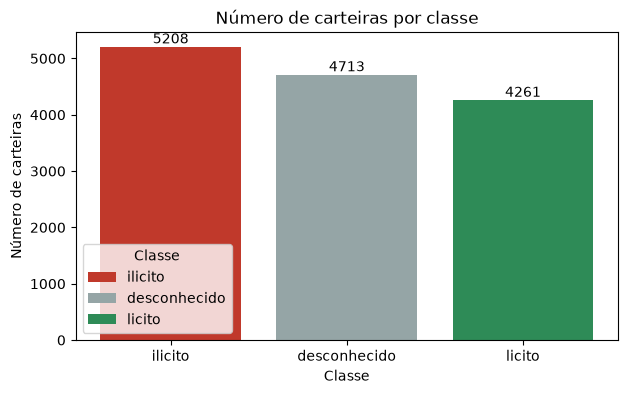

In [21]:
# [IA] Claude Code – código do gráfico 1 (tipo escolhido pelo Vagner: barras das classes)
contagem = nos["classe"].value_counts()[ORDEM]

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(ORDEM, contagem, color=[CORES[c] for c in ORDEM], label=ORDEM)
ax.bar_label(barras)
ax.set_title("Número de carteiras por classe")
ax.set_xlabel("Classe")
ax.set_ylabel("Número de carteiras")
ax.legend(title="Classe")
plt.savefig(SAIDA + "exploratoria_1.png", dpi=150, bbox_inches="tight")
plt.show()

**Nota analítica do gráfico 1 (Vagner)**

O gráfico mostra que as três classes têm quantidades parecidas de carteiras. A classe ilícita é a maior, com 5.208 carteiras, seguida pela classe desconhecida, com 4.713, e pela lícita, com 4.261. Portanto, nenhuma classe está muito acima das outras. Mesmo assim, é importante lembrar que esses números representam apenas o recorte analisado, e não toda a rede Bitcoin.

Esse gráfico foi escolhido pois dá para ter uma boa visualização de quão próximo são o lícito, ilícito e desconhecido no número de carteiras. Por isso foi iniciado em 0 a contagem na barra.

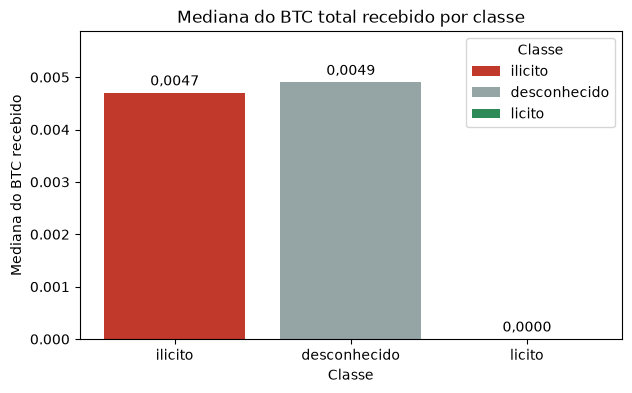

In [22]:
# [IA] Claude Code – código do gráfico 2 (tipo e atributo escolhidos pelo Vagner: barras com a mediana do BTC recebido por classe)
mediana_recebido = nos.groupby("classe")["btc_received_total"].median().loc[ORDEM]

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(ORDEM, mediana_recebido, color=[CORES[c] for c in ORDEM], label=ORDEM)
ax.bar_label(barras, labels=[f"{v:.4f}".replace(".", ",") for v in mediana_recebido], padding=3)
ax.set_ylim(0, mediana_recebido.max() * 1.2)
ax.set_title("Mediana do BTC total recebido por classe")
ax.set_xlabel("Classe")
ax.set_ylabel("Mediana do BTC recebido")
ax.legend(title="Classe")
plt.savefig(SAIDA + "exploratoria_2.png", dpi=150, bbox_inches="tight")
plt.show()

**Nota analítica do gráfico 2 (Vagner)**

O gráfico compara a mediana do BTC recebido por classe. As carteiras desconhecidas apresentam o maior valor, com 0,0049 BTC, seguidas pelas ilícitas, com 0,0047 BTC. Já as carteiras lícitas têm mediana igual a 0. Isso mostra que, no recorte analisado, as carteiras desconhecidas e ilícitas recebem valores típicos parecidos, enquanto as lícitas apresentam um valor muito menor.

Escolhi o gráfico de barras porque ele facilita a visualização e a comparação entre os tipos de carteira. A altura das barras mostra rapidamente qual classe tem a maior ou menor mediana, enquanto as cores e os valores escritos acima delas ajudam a identificar cada classe.





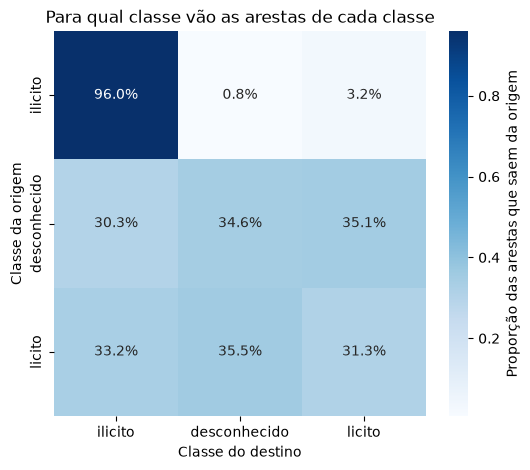

In [23]:
# [IA] Claude Code – código do gráfico 3 (tipo escolhido pelo Vagner: heatmap origem × destino)
tabela = pd.crosstab(arestas["classe_origem"], arestas["classe_destino"], normalize="index")
tabela = tabela.loc[ORDEM, ORDEM]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela, annot=True, fmt=".1%", cmap="Blues", ax=ax,
            cbar_kws={"label": "Proporção das arestas que saem da origem"})
ax.set_title("Para qual classe vão as arestas de cada classe")
ax.set_xlabel("Classe do destino")
ax.set_ylabel("Classe da origem")
plt.savefig(SAIDA + "exploratoria_3.png", dpi=150, bbox_inches="tight")
plt.show()


**Nota analítica do gráfico 3 (Vagner)**

O gráfico mostra para quais classes vão as arestas que saem de cada tipo de carteira. As carteiras ilícitas se conectam principalmente com outras ilícitas: 96% das suas arestas chegam nessa mesma classe. Já as carteiras desconhecidas e lícitas distribuem suas conexões de forma mais equilibrada entre as três classes, com valores próximos de um terço para cada uma. Isso mostra uma forte concentração das conexões entre carteiras ilícitas.

Esse gráfico foi escolhido pois é de fácil visualização perceber o quanto as outras carteiras vão para distintas carteiras de forma quase que igual entre elas e a carteira ilícita vai praticamente apenas para a carteira ilícita.

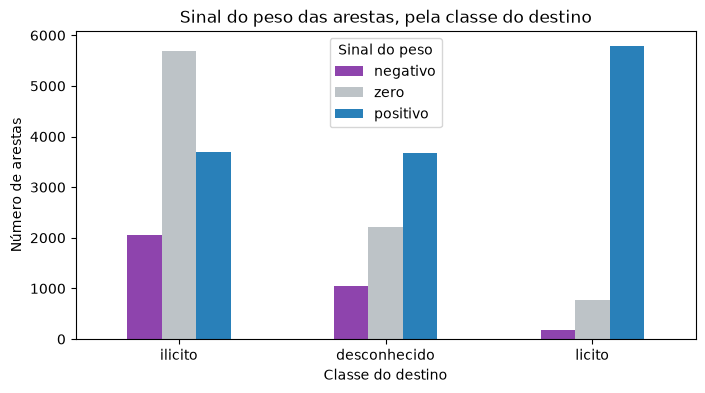

In [24]:
# [IA] Claude Code – código do gráfico 4 (tipo escolhido pelo Vagner: sinal dos pesos por classe do destino)
arestas["sinal_peso"] = np.sign(arestas["peso"]).map({-1: "negativo", 0: "zero", 1: "positivo"})
sinais = pd.crosstab(arestas["classe_destino"], arestas["sinal_peso"])
sinais = sinais.loc[ORDEM, ["negativo", "zero", "positivo"]]

fig, ax = plt.subplots(figsize=(8, 4))
sinais.plot(kind="bar", ax=ax, color=["#8e44ad", "#bdc3c7", "#2980b9"], rot=0)
ax.set_title("Sinal do peso das arestas, pela classe do destino")
ax.set_xlabel("Classe do destino")
ax.set_ylabel("Número de arestas")
ax.legend(title="Sinal do peso")
plt.savefig(SAIDA + "exploratoria_4.png", dpi=150, bbox_inches="tight")
plt.show()

**Nota analítica do gráfico 4 (Vagner)**

O gráfico mostra o sinal do peso das arestas de acordo com a classe da carteira de destino. Nas carteiras ilícitas, predominam os pesos zero, mas também há uma quantidade relevante de pesos positivos e negativos. Nas carteiras desconhecidas, os pesos positivos são maioria, seguidos pelos pesos zero e negativos. Já nas carteiras lícitas, uma grande maioria têm peso positivo, com poucos casos de peso zero ou negativo. Portanto, os pesos positivos aparecem principalmente nas carteiras lícitas, enquanto os pesos negativos são mais comuns nas carteiras ilícitas e desconhecidas.

Esse gráfico foi escolhido pois é de fácil visualização em ver o peso de cada aresta dependendo do tipo, pois com as barras agrupadas, dá pra ver sinais entre as classes.

## 8. Gráficos explanatórios (≥ 2)

Falta fazer

In [25]:
# [IA] Claude Code – código que combina a bfs do grupo para marcar as carteiras em ciclo e a CFC; critério definido pelo Vagner
import sys
sys.path.insert(0, os.path.abspath("../.."))
from src.graphs.graph import Grafo
from src.graphs.algorithms import bfs, dfs

grafo = Grafo()
for endereco in nos["endereco"]:
    grafo.adicionar_no(endereco)
for origem, destino, peso in zip(arestas["origem"], arestas["destino"], arestas["peso"]):
    grafo.adicionar_aresta(origem, destino, peso)

# quem envia para cada carteira (pandas)
predecessores = arestas.groupby("destino")["origem"].agg(set)
candidatas = nos.loc[(nos["grau_entrada"] > 0) & (nos["grau_saida"] > 0), "endereco"]

# a carteira está em ciclo se a bfs do grupo, partindo dela, alcança alguém que envia para ela
alcance = {}
for carteira in candidatas:
    alcancadas = set(bfs(grafo, carteira)["ordem"])
    if predecessores[carteira] & alcancadas:
        alcance[carteira] = alcancadas

# CFC = alcançáveis no grafo ∩ alcançáveis no transposto (as duas pela bfs do grupo)
transposto = grafo.transposto()
componente = {}
for carteira, alcancadas in alcance.items():
    if carteira not in componente:
        cfc = alcancadas & set(bfs(transposto, carteira)["ordem"])
        for membro in cfc:
            componente[membro] = carteira

nos["componente"] = nos["endereco"].map(componente)
nos["tamanho_componente"] = nos["componente"].map(nos["componente"].value_counts()).fillna(1).astype(int)
nos["em_ciclo"] = nos["componente"].notna()

print("Carteiras analisadas (recebem e enviam):", len(candidatas))
print("Carteiras em algum ciclo:", int(nos["em_ciclo"].sum()))
print("CFCs com mais de uma carteira:", nos["componente"].nunique())
nos.loc[nos["em_ciclo"], "classe"].value_counts()

Carteiras analisadas (recebem e enviam): 4072
Carteiras em algum ciclo: 116
CFCs com mais de uma carteira: 1


classe
licito          83
desconhecido    33
Name: count, dtype: int64

In [26]:
# [IA] Claude Code – código dos ciclos de 2 carteiras (A → B → A); ideia de analisá-los definida pelo Vagner
peso_arco = dict(zip(zip(arestas["origem"], arestas["destino"]), arestas["peso"]))
ciclos2 = pd.DataFrame(
    [(a, b, peso_arco[(a, b)] + peso_arco[(b, a)])
     for (a, b) in peso_arco if (b, a) in peso_arco and a < b],
    columns=["carteira_a", "carteira_b", "peso_ciclo"],
)
ciclos2["classe_a"] = ciclos2["carteira_a"].map(classe)
ciclos2["classe_b"] = ciclos2["carteira_b"].map(classe)
ciclos2["negativo"] = ciclos2["peso_ciclo"] < 0
ciclos2

,carteira_a,carteira_b,peso_ciclo,classe_a,classe_b,negativo
0,12cgpFdJViXbwHbhrA3TuW1EGnL25Zqc3P,1DEcTtkrbdXxS1wbrMvzub5X4VpByYmAwo,-13226.151644,licito,desconhecido,True
1,1317phRG67SrHduMYcK5AiX64NUNRCaKbb,1MFXYK1XucKFfhPhW9HDHD3vsM9BKey4qm,-1674.017388,licito,desconhecido,True
2,16YnMmhhYUiDftLWMWVBZt3s1vFKXefHHQ,1MFXYK1XucKFfhPhW9HDHD3vsM9BKey4qm,-1675.042338,licito,desconhecido,True
3,18k5dMBkKnHz4C285BSDCTidyFV6NUSP84,1MFXYK1XucKFfhPhW9HDHD3vsM9BKey4qm,-1674.017388,licito,desconhecido,True
4,18pDk9kgcRm2U3rp2W5AnsfTz2PzQ33iPL,1MFXYK1XucKFfhPhW9HDHD3vsM9BKey4qm,-1674.017388,licito,desconhecido,True
5,1Az1tkD7CpNiM2tgLCMhhvSEvXRwhdiUSc,1MFXYK1XucKFfhPhW9HDHD3vsM9BKey4qm,-1674.017388,licito,desconhecido,True
6,1DiHnMqauUQ9Pcjv5wj6CryjL7EACuSQJE,1MFXYK1XucKFfhPhW9HDHD3vsM9BKey4qm,-1674.017388,licito,desconhecido,True
7,1MFXYK1XucKFfhPhW9HDHD3vsM9BKey4qm,1NvGscWgZF4tfG32P64BZraF7NJPGjCPU2,-1674.017388,desconhecido,licito,True
8,1MUFg78a6EDGzV79FUrwipsJUCGnnVcLM4,3E1RUgX9KK49q16gVmdc2dX2sU73masMzU,2.469071,desconhecido,desconhecido,False


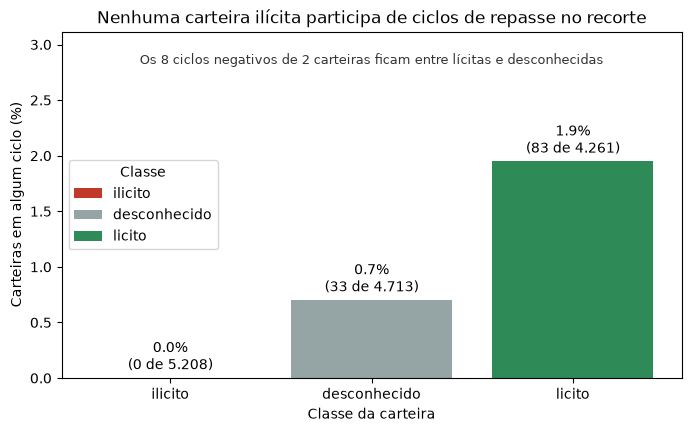

In [27]:
# [IA] Claude Code – sintaxe matplotlib do explanatório 1; tipo de gráfico, título, anotação e cores definidos pelo Vagner
em_ciclo = nos.groupby("classe")["em_ciclo"].agg(["sum", "count"]).loc[ORDEM]
em_ciclo["pct"] = 100 * em_ciclo["sum"] / em_ciclo["count"]
rotulos = [f"{p:.1f}%\n({s:,} de {t:,})".replace(",", ".")
           for p, s, t in zip(em_ciclo["pct"], em_ciclo["sum"], em_ciclo["count"])]

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(ORDEM, em_ciclo["pct"], color=[CORES[c] for c in ORDEM], label=ORDEM)
ax.bar_label(barras, labels=rotulos, padding=3)
ax.set_ylim(0, em_ciclo["pct"].max() * 1.6)
ax.set_title("Nenhuma carteira ilícita participa de ciclos de repasse no recorte")
ax.set_xlabel("Classe da carteira")
ax.set_ylabel("Carteiras em algum ciclo (%)")
ax.legend(title="Classe", loc="center left")
n_neg = int(ciclos2["negativo"].sum())
ax.text(1, em_ciclo["pct"].max() * 1.45,
        f"Os {n_neg} ciclos negativos de 2 carteiras ficam entre lícitas e desconhecidas",
        ha="center", fontsize=9, color="#333")
plt.savefig(SAIDA + "explanatoria_1.png", dpi=150, bbox_inches="tight")
plt.show()

**Nota analítica do explanatório 1 (Vagner)**

Falta fazer

In [28]:
# [IA] Claude Code – código do papel no fluxo e da dfs do grupo no subgrafo das ilícitas; variáveis definidas pelo Vagner
nos["papel"] = np.select(
    [(nos["grau_entrada"] > 0) & (nos["grau_saida"] > 0), nos["grau_saida"] > 0, nos["grau_entrada"] > 0],
    ["recebe e repassa", "só envia", "só recebe"],
    "isolada",
)
PAPEIS = ["recebe e repassa", "só envia", "só recebe"]
papeis = pd.crosstab(nos["classe"], nos["papel"], normalize="index").loc[ORDEM, PAPEIS] * 100

ilicitas = nos.loc[nos["classe"] == "ilicito", "endereco"]
grafo_ilicitas = grafo.subgrafo_induzido(ilicitas)
dfs_ilicitas = dfs(grafo_ilicitas)
print("Arestas entre ilícitas:", grafo_ilicitas.tamanho())
print("DFS no subgrafo das ilícitas – tem ciclo?", dfs_ilicitas["tem_ciclo"])
print("Arcos de retorno:", dfs_ilicitas["contagem_arcos"]["retorno"])
papeis.round(1)

Arestas entre ilícitas: 5208
DFS no subgrafo das ilícitas – tem ciclo? False
Arcos de retorno: 0


papel,recebe e repassa,só envia,só recebe
classe,,,
ilicito,54.5,37.3,8.2
desconhecido,21.7,67.4,10.9
licito,4.9,68.1,27.0


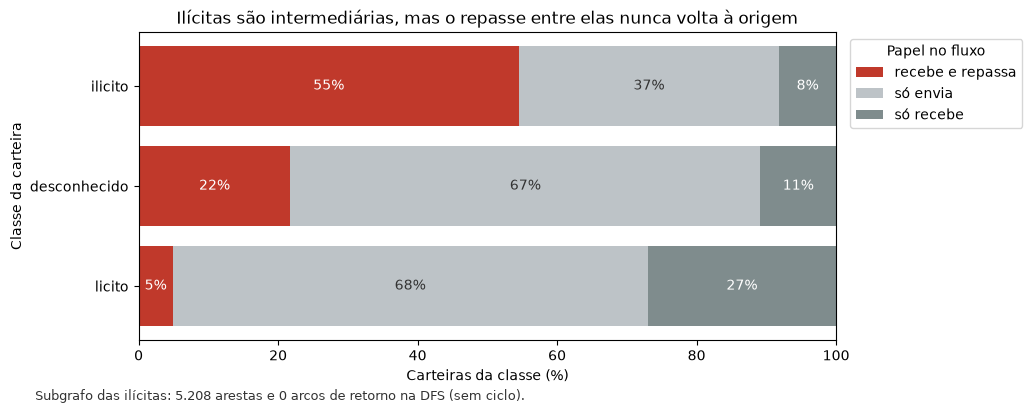

In [29]:
# [IA] Claude Code – sintaxe matplotlib do explanatório 2; tipo de gráfico, título, nota de rodapé e cor de destaque de "recebe e repassa" definidos pelo Vagner
CORES_PAPEL = {"recebe e repassa": "#c0392b", "só envia": "#bdc3c7", "só recebe": "#7f8c8d"}

fig, ax = plt.subplots(figsize=(9, 4))
esquerda = np.zeros(len(ORDEM))
for papel in PAPEIS:
    barras = ax.barh(ORDEM, papeis[papel], left=esquerda, color=CORES_PAPEL[papel], label=papel)
    ax.bar_label(barras, labels=[f"{v:.0f}%" for v in papeis[papel]],
                 label_type="center", color="#333" if papel == "só envia" else "white")
    esquerda += papeis[papel].values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_title("Ilícitas são intermediárias, mas o repasse entre elas nunca volta à origem")
ax.set_xlabel("Carteiras da classe (%)")
ax.set_ylabel("Classe da carteira")
ax.legend(title="Papel no fluxo", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.text(0.01, -0.04,
         f"Subgrafo das ilícitas: {grafo_ilicitas.tamanho():,} arestas e "
         f"{dfs_ilicitas['contagem_arcos']['retorno']} arcos de retorno na DFS (sem ciclo).".replace(",", "."),
         fontsize=9, color="#333")
plt.savefig(SAIDA + "explanatoria_2.png", dpi=150, bbox_inches="tight")
plt.show()

**Nota analítica do explanatório 2 (Vagner)**

Falta fazer

## 9. Da exploração à explicação

Falta fazer